<a href="https://colab.research.google.com/github/mariatomilova19088-prog/cpp-practice-2026/blob/main/face_eye_cpp_Tomilova.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ДЗ5 Распознавание лиц и глаз

In [34]:
%%bash
set -e
apt-get update
apt-get install -y g++ pkg-config libopencv-dev libcurl4-openssl-dev
pkg-config --modversion opencv4

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:4 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Fetched 3,917 B in 1s (5,054 B/s)
Reading package lists...
Reading package lists...
Building dependency tree...
Reading state information...
g++ is already the newest version (4:13.2.0-7ubuntu1).
pkg-config is already the newest version (1.8.1-2build1).
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
libcurl4-openssl-dev is already the newest version (8.5.0-2ubuntu10.16).
0 upgraded, 0 newly installed, 0 to remove and 77 not upgraded.
4.6.0


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [35]:
%%writefile detect_faces.cpp
#include <iostream>
#include <vector>
#include <string>
#include <opencv2/opencv.hpp>
#include <opencv2/objdetect.hpp>
#include <curl/curl.h>

size_t WriteMemoryCallback(void* contents, size_t size, size_t nmemb, void* userp) {
    size_t realsize = size * nmemb;
    auto* mem = static_cast<std::vector<uchar>*>(userp);
    auto* ptr = static_cast<uchar*>(contents);
    mem->insert(mem->end(), ptr, ptr + realsize);
    return realsize;
}

std::vector<uchar> download(const std::string& url) {
    std::vector<uchar> data;
    CURL* curl = curl_easy_init();
    if (curl) {
        curl_easy_setopt(curl, CURLOPT_URL, url.c_str());
        curl_easy_setopt(curl, CURLOPT_WRITEFUNCTION, WriteMemoryCallback);
        curl_easy_setopt(curl, CURLOPT_WRITEDATA, &data);
        curl_easy_setopt(curl, CURLOPT_FOLLOWLOCATION, 1L);
        curl_easy_setopt(curl, CURLOPT_USERAGENT, "libcurl-agent/1.0");
        curl_easy_perform(curl);
        curl_easy_cleanup(curl);
    }
    return data;
}

// Универсальная загрузка: URL или локальный файл
cv::Mat loadImage(const std::string& source) {
    if (source.rfind("http", 0) == 0) {
        auto bytes = download(source);
        return cv::imdecode(bytes, cv::IMREAD_COLOR);
    }
    return cv::imread(source);
}

int main(int argc, char** argv) {
    // Источник: аргумент командной строки, иначе — URL по умолчанию
    std::string source = (argc > 1) ? argv[1]
        : "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg";

    std::cout << "Loading: " << source << std::endl;
    cv::Mat image = loadImage(source);
    if (image.empty()) {
        std::cerr << "Failed to load image from: " << source << std::endl;
        return 1;
    }
    std::cout << "Image: " << image.cols << "x" << image.rows << std::endl;

    // Каскады
    cv::CascadeClassifier face_cascade, eye_cascade;
    if (!face_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_frontalface_default.xml") ||
        !eye_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_eye.xml")) {
        std::cerr << "Cannot load cascades" << std::endl;
        return 1;
    }

    // Подготовка
    cv::Mat gray;
    cv::cvtColor(image, gray, cv::COLOR_BGR2GRAY);
    cv::equalizeHist(gray, gray);

    // Детекция лиц — вернёт ВСЕ найденные лица
    std::vector<cv::Rect> faces;
    face_cascade.detectMultiScale(
        gray, faces,
        /*scaleFactor*/  1.05,   // чуть меньше, чем 1.1 — ищем тщательнее (для групповых фото)
        /*minNeighbors*/ 5,
        /*flags*/        0,
        /*minSize*/      cv::Size(20, 20)   // маленькие лица тоже ловим
    );

    std::cout << "Detected faces: " << faces.size() << std::endl;

    // Рисуем рамку + номер для каждого лица
    int idx = 0;
    int total_eyes = 0;
    for (const auto& face : faces) {
        ++idx;
        cv::rectangle(image, face, cv::Scalar(0, 255, 0), 2);

        // Подпись "Face N" над рамкой
        std::string label = "Face " + std::to_string(idx);
        int baseline = 0;
        cv::Size text_size = cv::getTextSize(label, cv::FONT_HERSHEY_SIMPLEX, 0.6, 2, &baseline);
        cv::Point text_org(face.x, face.y - 5);
        if (text_org.y < text_size.height) text_org.y = face.y + text_size.height + 5;

        cv::rectangle(image,
                      cv::Point(text_org.x, text_org.y - text_size.height - 2),
                      cv::Point(text_org.x + text_size.width, text_org.y + 2),
                      cv::Scalar(0, 255, 0), cv::FILLED);
        cv::putText(image, label, text_org, cv::FONT_HERSHEY_SIMPLEX, 0.6,
                    cv::Scalar(0, 0, 0), 2);

        // Глаза ищем только в верхних 60% лица (там они и находятся)
        cv::Mat face_roi_gray  = gray(face);
        cv::Mat face_roi_gray_top = face_roi_gray(cv::Rect(0, 0, face.width, face.height * 6 / 10));

        std::vector<cv::Rect> eyes;
        eye_cascade.detectMultiScale(face_roi_gray_top, eyes, 1.1, 10);
        total_eyes += eyes.size();
        for (const auto& eye : eyes) {
            cv::Rect eye_abs(face.x + eye.x, face.y + eye.y, eye.width, eye.height);
            cv::rectangle(image, eye_abs, cv::Scalar(255, 0, 0), 2);
        }
    }

    std::cout << "Detected eyes: " << total_eyes << std::endl;
    cv::imwrite("faces_detected.jpg", image);
    std::cout << "Result saved: faces_detected.jpg" << std::endl;

    if (faces.empty()) {
        std::cerr << "No faces detected. Try another image or lower minNeighbors." << std::endl;
        return 0;
    }
    return 0;
}

Overwriting detect_faces.cpp


In [36]:
!g++ detect_faces.cpp -o detect_faces -std=c++17 $(pkg-config --cflags --libs opencv4 libcurl)
!ls -l detect_faces

-rwxr-xr-x 1 root root 64944 Nov 24 21:03 detect_faces


## Подготовка фотографий
Три независимых снимка из наборов примеров scikit-image и Matplotlib. Python используется только для подготовки файлов, запуска C++ и отображения.

In [37]:
from skimage import data
from matplotlib.cbook import get_sample_data
from PIL import Image
import matplotlib.pyplot as plt
import cv2
import subprocess
import re

Image.fromarray(data.astronaut()).save("photo1.png")
Image.open(get_sample_data("grace_hopper.jpg", asfileobj=False)).save("photo2.png")
Image.fromarray(data.camera()).save("photo3.png")
results = []

def show_result(source, actual_faces, actual_eyes):
    run = subprocess.run(["./detect_faces", source], check=True, capture_output=True, text=True)
    print(run.stdout)
    faces = int(re.search(r"Detected faces: (\d+)", run.stdout).group(1))
    eyes = int(re.search(r"Detected eyes: (\d+)", run.stdout).group(1))
    results.append((source, actual_faces, faces, actual_eyes, eyes))
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    for ax, path, title in zip(axes, [source, "faces_detected.jpg"], ["Исходное фото", "Результат C++"]):
        ax.imshow(cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis("off")
    plt.show()

## Эксперимент 1. Портрет космонавта
Вручную: лиц — 1, видимых глаз — 2. Зелёная рамка — лицо, синяя — глаз.

Loading: photo1.png
Image: 512x512
Detected faces: 2
Detected eyes: 2
Result saved: faces_detected.jpg



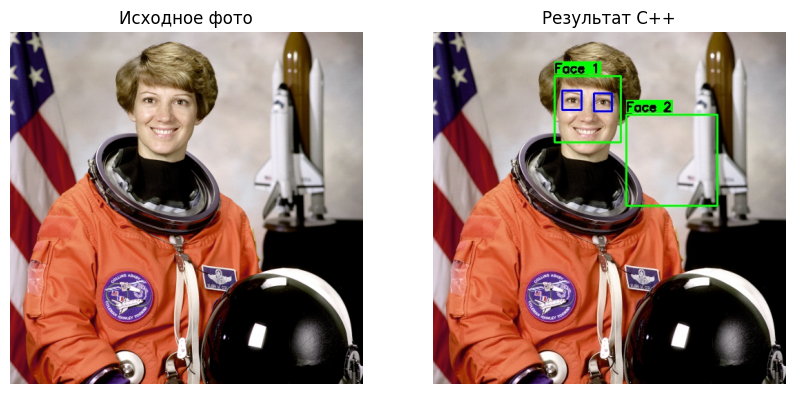

In [38]:
show_result("photo1.png", 1, 2)

## Эксперимент 2. Портрет в форме
Вручную: лиц — 1, видимых глаз — 2. Зелёная рамка — лицо, синяя — глаз.

Loading: photo2.png
Image: 512x600
Detected faces: 1
Detected eyes: 0
Result saved: faces_detected.jpg



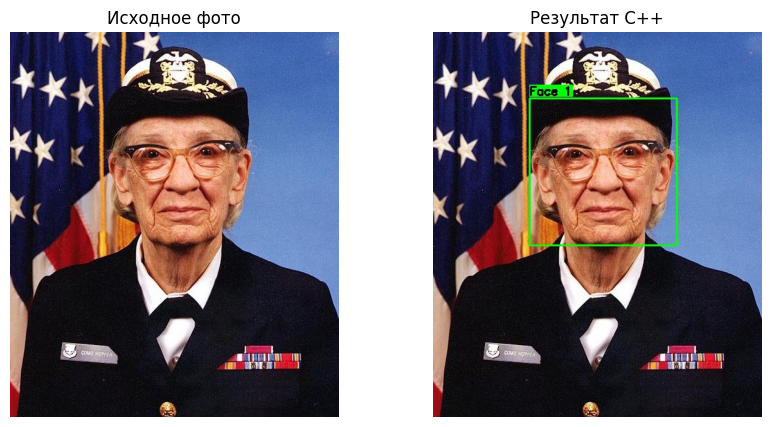

In [39]:
show_result("photo2.png", 1, 2)

## Эксперимент 3. Человек в профиль
Вручную: лиц — 1, видимых глаз — 1. Зелёная рамка — лицо, синяя — глаз.

Loading: photo3.png
Image: 512x512
Detected faces: 1
Detected eyes: 0
Result saved: faces_detected.jpg



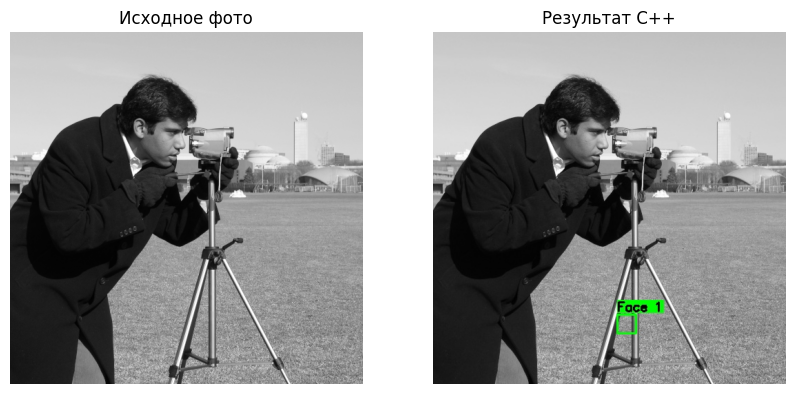

In [40]:
show_result("photo3.png", 1, 1)

## Сравнение результатов
Предварительные результаты получены через Python API OpenCV 4.13 с параметрами преподавателя. После запуска ячеек в Colab таблица ниже будет заполнена фактическими результатами C++.

| Фото | Лиц на фото | Лиц найдено | Глаз на фото | Глаз найдено |
|---|---:|---:|---:|---:|
| 1 | 1 | 2 | 2 | 2 |
| 2 | 1 | 1 | 2 | 0 |
| 3 | 1 | 1 | 1 | 0 |

In [41]:
import pandas as pd
pd.DataFrame(results, columns=["Фото", "Лиц на фото", "Лиц найдено", "Глаз на фото", "Глаз найдено"]).drop_duplicates(subset="Фото", keep="last")

,Фото,Лиц на фото,Лиц найдено,Глаз на фото,Глаз найдено
0,photo1.png,1,2,2,2
1,photo2.png,1,1,2,0
2,photo3.png,1,1,1,0


## Вывод
В контрольном эксперименте 1 обнаружено лишнее лицо, но найдены оба глаза. Во втором опыте лицо найдено, глаза пропущены. В третьем опыте число рамок лиц совпало с ручным подсчётом, но рамка находится не на лице: это ложное срабатывание. Глаз в профиль не обнаружен.

Каскад фронтального лица лучше работает на лицах, обращённых к камере. Поворот головы, освещение, масштаб и тени влияют на результат. Глаза ищутся только в верхних 60% найденного лица. Значение minNeighbors=10 для глаз уменьшает число ложных срабатываний, но может приводить к пропускам. Поэтому важно сравнивать не только количество рамок, но и их положение.